# Validation 2 — Deformation of a ferrofluid droplet under a uniform magnetic field

Reproduces Hu, Li & Niu, *Phys. Rev. E* **98**, 033301 (2018), Sec. III B (Fig. 4 shapes, Fig. 5 b/a curve).

**Setup.** A circular ferrofluid droplet ($\chi_0=2.2$, $R=12.5$) in organic liquid, in a uniform
static field applied along $+x$ (Route 1: the paper applies it along $+y$; the deformation is
isotropic, so b/a is unchanged and the droplet simply elongates along $x$). Flow is **on**; the
droplet relaxes to an ellipse set by the competition of magnetic and capillary stress.

**Reduction used.** $\mathbf M=\phi M_s L(\xi_e)\hat{\boldsymbol\xi}_e$; for $\xi_e\ll1$,
$\chi_{\rm eff}=\phi M_s\xi_{\rm per H}/3$. The constraint $M_s\xi_{\rm per H}=3\chi_0=6.6$ gives
$\chi_{\rm eff}=\chi_0$ in the droplet ($\phi=1$) and $0$ outside ($\phi=0$) automatically.

**Governing dimensionless group.** The equilibrium aspect ratio is set by the magnetic Bond number
$$\mathrm{Bo}_m=\frac{\mu_0\chi_0^2 H^2 R}{\sigma}.$$
The five lattice fields are $H_{\rm lat}\propto H_{\rm phys}$, so $\mathrm{Bo}_m\propto H_{\rm phys}^2$
matches the paper case by case; the common scale is one calibration knob.

**Target (paper Fig. 5), b/a vs H (kA/m):** ~1.05 (1.2), ~1.45 (2.4), ~1.8 (2.9), ~2.5 (3.7), ~5.3 (5.5).


In [ ]:
import numpy as np, pandas as pd, glob, os
import matplotlib.pyplot as plt
from scipy import interpolate

SWEEP_DIR = "sweep"
NX = NY = 400   # must match the .cpp domain size
NSTEPS = 60000                 # must match the .cpp / shell script
man = pd.read_csv(os.path.join(SWEEP_DIR, "manifest.csv"))
print(man.to_string(index=False))

## 1. Aspect-ratio measurement at the $\phi=0.5$ contour

`b` = half-extent of the droplet along the field ($x$); `a` = half-extent across it ($y$).
Each is found by sub-pixel interpolation of the $\phi=0.5$ crossing along the centre lines.

In [12]:
def load_phi(path):
    df = pd.read_csv(path)
    return df.pivot(index='j', columns='i', values='phi').values, df

def load_field(path):
    df = pd.read_csv(path)
    ux = df.pivot(index='j', columns='i', values='ux').values
    uy = df.pivot(index='j', columns='i', values='uy').values
    return ux, uy

def half_extent(phi1d):
    # distance from centre to the phi=0.5 crossing, sub-pixel, along a 1D line
    c = (len(phi1d) - 1) / 2.0
    # march out+ from centre until phi drops below 0.5, linearly interpolate
    idx = int(round(c))
    for k in range(idx, len(phi1d)-1):
        if phi1d[k] >= 0.5 and phi1d[k+1] < 0.5:
            frac = (phi1d[k] - 0.5) / (phi1d[k] - phi1d[k+1])
            return (k + frac) - c
    return np.nan

def measure_ba(phi):
    cy = (NY - 1) // 2
    cx = (NX - 1) // 2
    b = half_extent(phi[cy, :])   # along x (field) -> long axis
    a = half_extent(phi[:, cx])   # along y          -> short axis
    return b, a, b/a

rows = []
for _, r in man.iterrows():
    n = int(r['case'])
    phi, _ = load_phi(os.path.join(SWEEP_DIR, f"field_{n}_final.csv"))
    ux, uy = load_field(os.path.join(SWEEP_DIR, f"field_{n}_final.csv"))
    b, a, ba = measure_ba(phi)
    umax = float(np.nanmax(np.hypot(ux, uy)))
    rows.append(dict(case=n, H_kAm=r['H_phys_kAm'], b=round(b,2), a=round(a,2),
                     ba=round(ba,3), max_u=umax))
res = pd.DataFrame(rows)
print(res.to_string(index=False))
print("\\nEquilibrium check: max|u| should be << the peak transient (~1e-3). "
      "If not, increase nSteps in the .cpp and rerun.")

 case  H_kAm     b     a    ba    max_u
    1    1.2 12.89 12.10 1.065 0.000537
    2    2.4 14.27 10.90 1.309 0.002061
    3    2.9 15.30 10.12 1.512 0.002878
    4    3.7 17.76  8.58 2.070 0.004199
    5    5.5 26.19  5.45 4.802 0.006933
\nEquilibrium check: max|u| should be << the peak transient (~1e-3). If not, increase nSteps in the .cpp and rerun.


## 2. Reproduce Fig. 4 — equilibrium droplet shapes

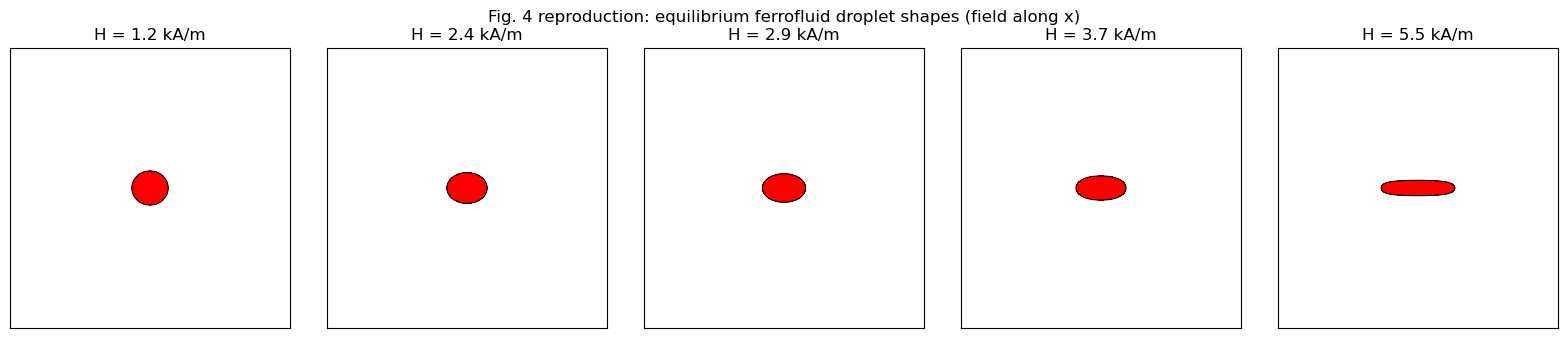

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
labels = ['1.2', '2.4', '2.9', '3.7', '5.5']
for ax, (_, r) in zip(axes, man.iterrows()):
    n = int(r['case'])
    phi, _ = load_phi(os.path.join(SWEEP_DIR, f"field_{n}_final.csv"))
    ax.contourf(phi, levels=[0.5, 1.0], colors=['red'])
    ax.contour(phi, levels=[0.5], colors=['k'], linewidths=0.8)
    ax.set_title(f'H = {labels[n-1]} kA/m'); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Fig. 4 reproduction: equilibrium ferrofluid droplet shapes (field along x)')
plt.tight_layout(); plt.savefig('droplet_fig4.png', dpi=130); plt.show()

## 3. Reproduce Fig. 5 — b/a vs applied field

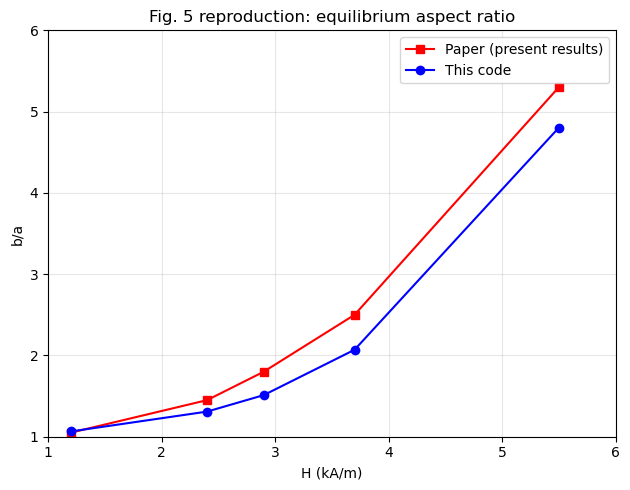

 H_kAm    ba  paper  err %
   1.2 1.065   1.05    1.4
   2.4 1.309   1.45   -9.7
   2.9 1.512   1.80  -16.0
   3.7 2.070   2.50  -17.2
   5.5 4.802   5.30   -9.4


In [14]:
# paper Fig. 5 present-results, read off the plotted curve
paper_H  = [1.2, 2.4, 2.9, 3.7, 5.5]
paper_ba = [1.05, 1.45, 1.8, 2.5, 5.3]

plt.figure(figsize=(6.4, 5))
plt.plot(paper_H, paper_ba, 'rs-', label='Paper (present results)', ms=6)
plt.plot(res['H_kAm'], res['ba'], 'bo-', label='This code', ms=6)
plt.xlabel('H (kA/m)'); plt.ylabel('b/a'); plt.xlim(1, 6); plt.ylim(1, 6)
plt.legend(); plt.grid(alpha=0.3)
plt.title('Fig. 5 reproduction: equilibrium aspect ratio')
plt.tight_layout(); plt.savefig('droplet_fig5.png', dpi=130); plt.show()

cmp = res[['H_kAm','ba']].copy()
cmp['paper'] = paper_ba
cmp['err %'] = (100*(cmp['ba']-cmp['paper'])/cmp['paper']).round(1)
print(cmp.to_string(index=False))

## 4. Transient — b/a approach to equilibrium (sanity)

Confirms each case reached a steady shape rather than being stopped mid-relaxation.
If the last two time points still differ, the run needs more steps.

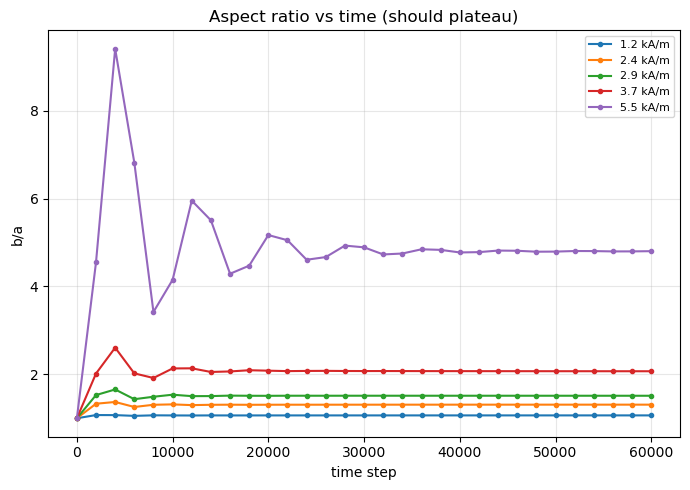

In [15]:
plt.figure(figsize=(7, 5))
for _, r in man.iterrows():
    n = int(r['case'])
    ts, bas = [], []
    for f in sorted(glob.glob(os.path.join(SWEEP_DIR, f"field_{n}_t_*.csv")),
                    key=lambda p:int(p.split('_t_')[1].split('.')[0])):
        t = int(f.split('_t_')[1].split('.')[0])
        phi, _ = load_phi(f)
        _, _, ba = measure_ba(phi)
        ts.append(t); bas.append(ba)
    plt.plot(ts, bas, 'o-', ms=3, label=f"{r['H_phys_kAm']} kA/m")
plt.xlabel('time step'); plt.ylabel('b/a'); plt.legend(fontsize=8)
plt.title('Aspect ratio vs time (should plateau)'); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('droplet_transient.png', dpi=130); plt.show()